# Warehouse navigation results and adaptation

We compare Q-Learning, DQN and a random policy on a fixed warehouse layout, then distinguish frozen transfer from adaptation through further training on a route-blocking layout. This notebook analyses saved logs; it does not select hyperparameters or retrain models.

## Setup and reproducibility
Run from the project folder or the notebook folder with the project virtual environment. Main experiments use 3000 episodes and seeds 0–9. The extension uses 1000 additional episodes per saved policy. Trained-policy reliability and random-policy episode success have different sampling units.

In [1]:
from pathlib import Path
import json, sys, csv
from IPython.display import display, Image, Markdown
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.json').exists() and (p / 'warehouse').is_dir())
sys.path.insert(0, str(root))
main = root / 'results/main'
adaptation = root / 'results/adaptation'
summary = json.loads((main / 'summary.json').read_text())
metadata = json.loads((main / 'metadata.json').read_text())
print('Recorded Python:', metadata['python'])
print('Recorded package versions:', metadata['versions'])
print('Main-layout BFS optimum:', summary['optimal_steps'])

Recorded Python: 3.12.14
Recorded package versions: {'numpy': '2.3.5', 'gymnasium': '1.4.0', 'torch': '2.14.1', 'matplotlib': '3.11.2', 'pygame': '2.6.1', 'pytest': '9.1.1'}
Main-layout BFS optimum: 18


## Main comparison
Use the final checkpoint from every seed. Values are descriptive means and sample standard deviations, not confidence intervals. Failure episodes remain in the overall length and return metrics.

In [2]:
display(Markdown((main / 'RESULTS.md').read_text()))

# Reproduced experimental results

BFS optimum: 18 steps; undiscounted return 23.20.

Final checkpoint only; epsilon=0; one rollout per independently trained policy.

| Method | Successful policies | Optimal policies | Return | Steps | Pooled collisions | Training seconds |
|---|---:|---:|---:|---:|---:|---:|
| q_learning | 10/10 | 10/10 | 23.20 ± 0.00 | 18.00 ± 0.00 | 0.00% | 0.314 ± 0.004 |
| dqn | 8/10 | 7/10 | 14.50 ± 18.18 | 55.00 ± 76.44 | 0.00% | 42.364 ± 20.522 |

Random baseline: 68/1000 episodes (6.8%); return -58.74 ± 14.72; all-episode steps 195.7 ± 19.1; successful steps 136.7 ± 40.7 (n=68); pooled collision rate 22.14%.

| Method | First successful check | Stable-optimal check | Runs reaching stable optimum | Steps to stable optimum | Total train steps |
|---|---:|---:|---:|---:|---:|
| q_learning | 53.0 ± 8.2 | 53.0 ± 8.2 | 10/10 | 9102 ± 1056 | 71346 ± 603 |
| dqn | 1416.2 ± 781.4 | 1681.4 ± 642.6 | 7/10 | 266932 ± 151649 | 370376 ± 174393 |

Standard deviations use ddof=1. Convergence means include only runs where the event was observed; failures are censored, not assigned zero. Stable means optimal at every subsequent recorded check through the training horizon. Checks occur every 10 episodes plus the final episode. Collision rates pool blocked moves over attempted moves.

## Training windows

Values below are mean ± sample std of per-seed window statistics. Exploration is included.

| Method | Episodes | Return | Success | Steps | Collision rate |
|---|---|---:|---:|---:|---:|
| q_learning | 1–100 | -18.86 ± 1.68 | 0.629 ± 0.032 | 128.7 ± 4.0 | 0.1800 ± 0.0041 |
| q_learning | 101–500 | 20.76 ± 0.29 | 1.000 ± 0.000 | 27.1 ± 0.6 | 0.0568 ± 0.0083 |
| q_learning | 2501–3000 | 22.94 ± 0.04 | 1.000 ± 0.000 | 19.0 ± 0.1 | 0.0084 ± 0.0017 |
| dqn | 1–100 | -51.57 ± 2.08 | 0.036 ± 0.036 | 198.2 ± 2.2 | 0.1710 ± 0.0110 |
| dqn | 101–500 | -26.57 ± 9.72 | 0.076 ± 0.222 | 188.1 ± 35.4 | 0.0539 ± 0.0142 |
| dqn | 2501–3000 | 13.52 ± 18.83 | 0.799 ± 0.421 | 56.4 ± 75.7 | 0.0203 ± 0.0178 |

Timing: training loop, including in-memory logging; excludes greedy checks, model creation, final evaluation and disk writes. See metadata.json for hardware, software versions and source hashes.

The rollout cap is treated as an external sampling cutoff of the underlying goal-reaching task. Both algorithms bootstrap on truncation; delivery termination alone masks the target. The measured success metric is delivery within 200 moves.


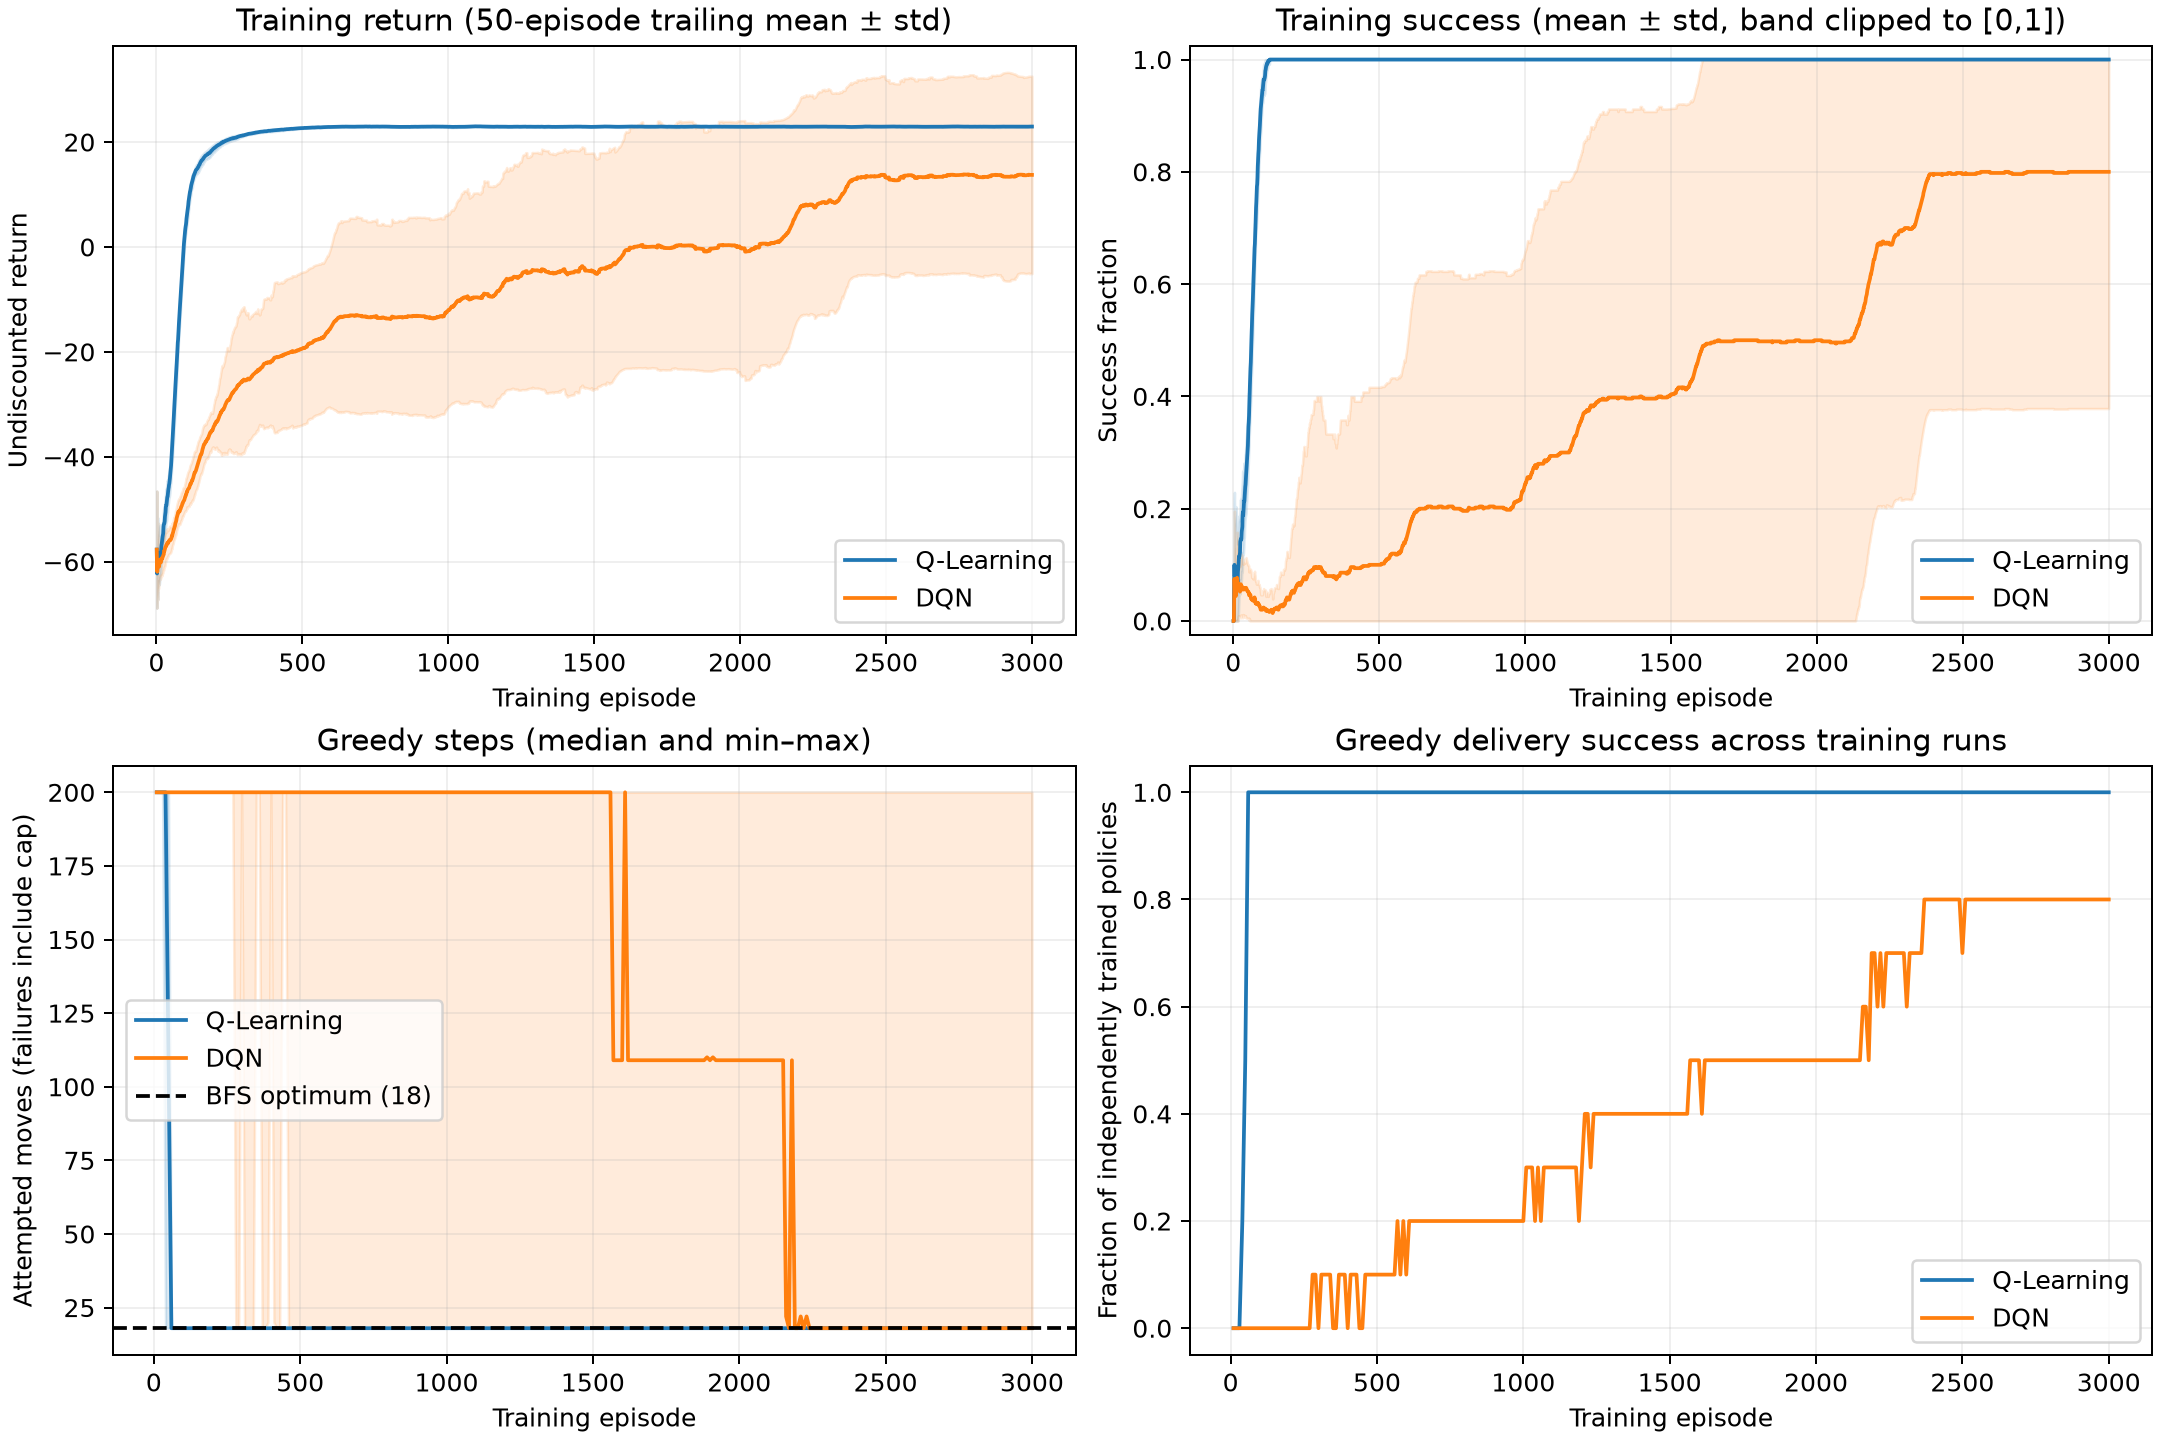

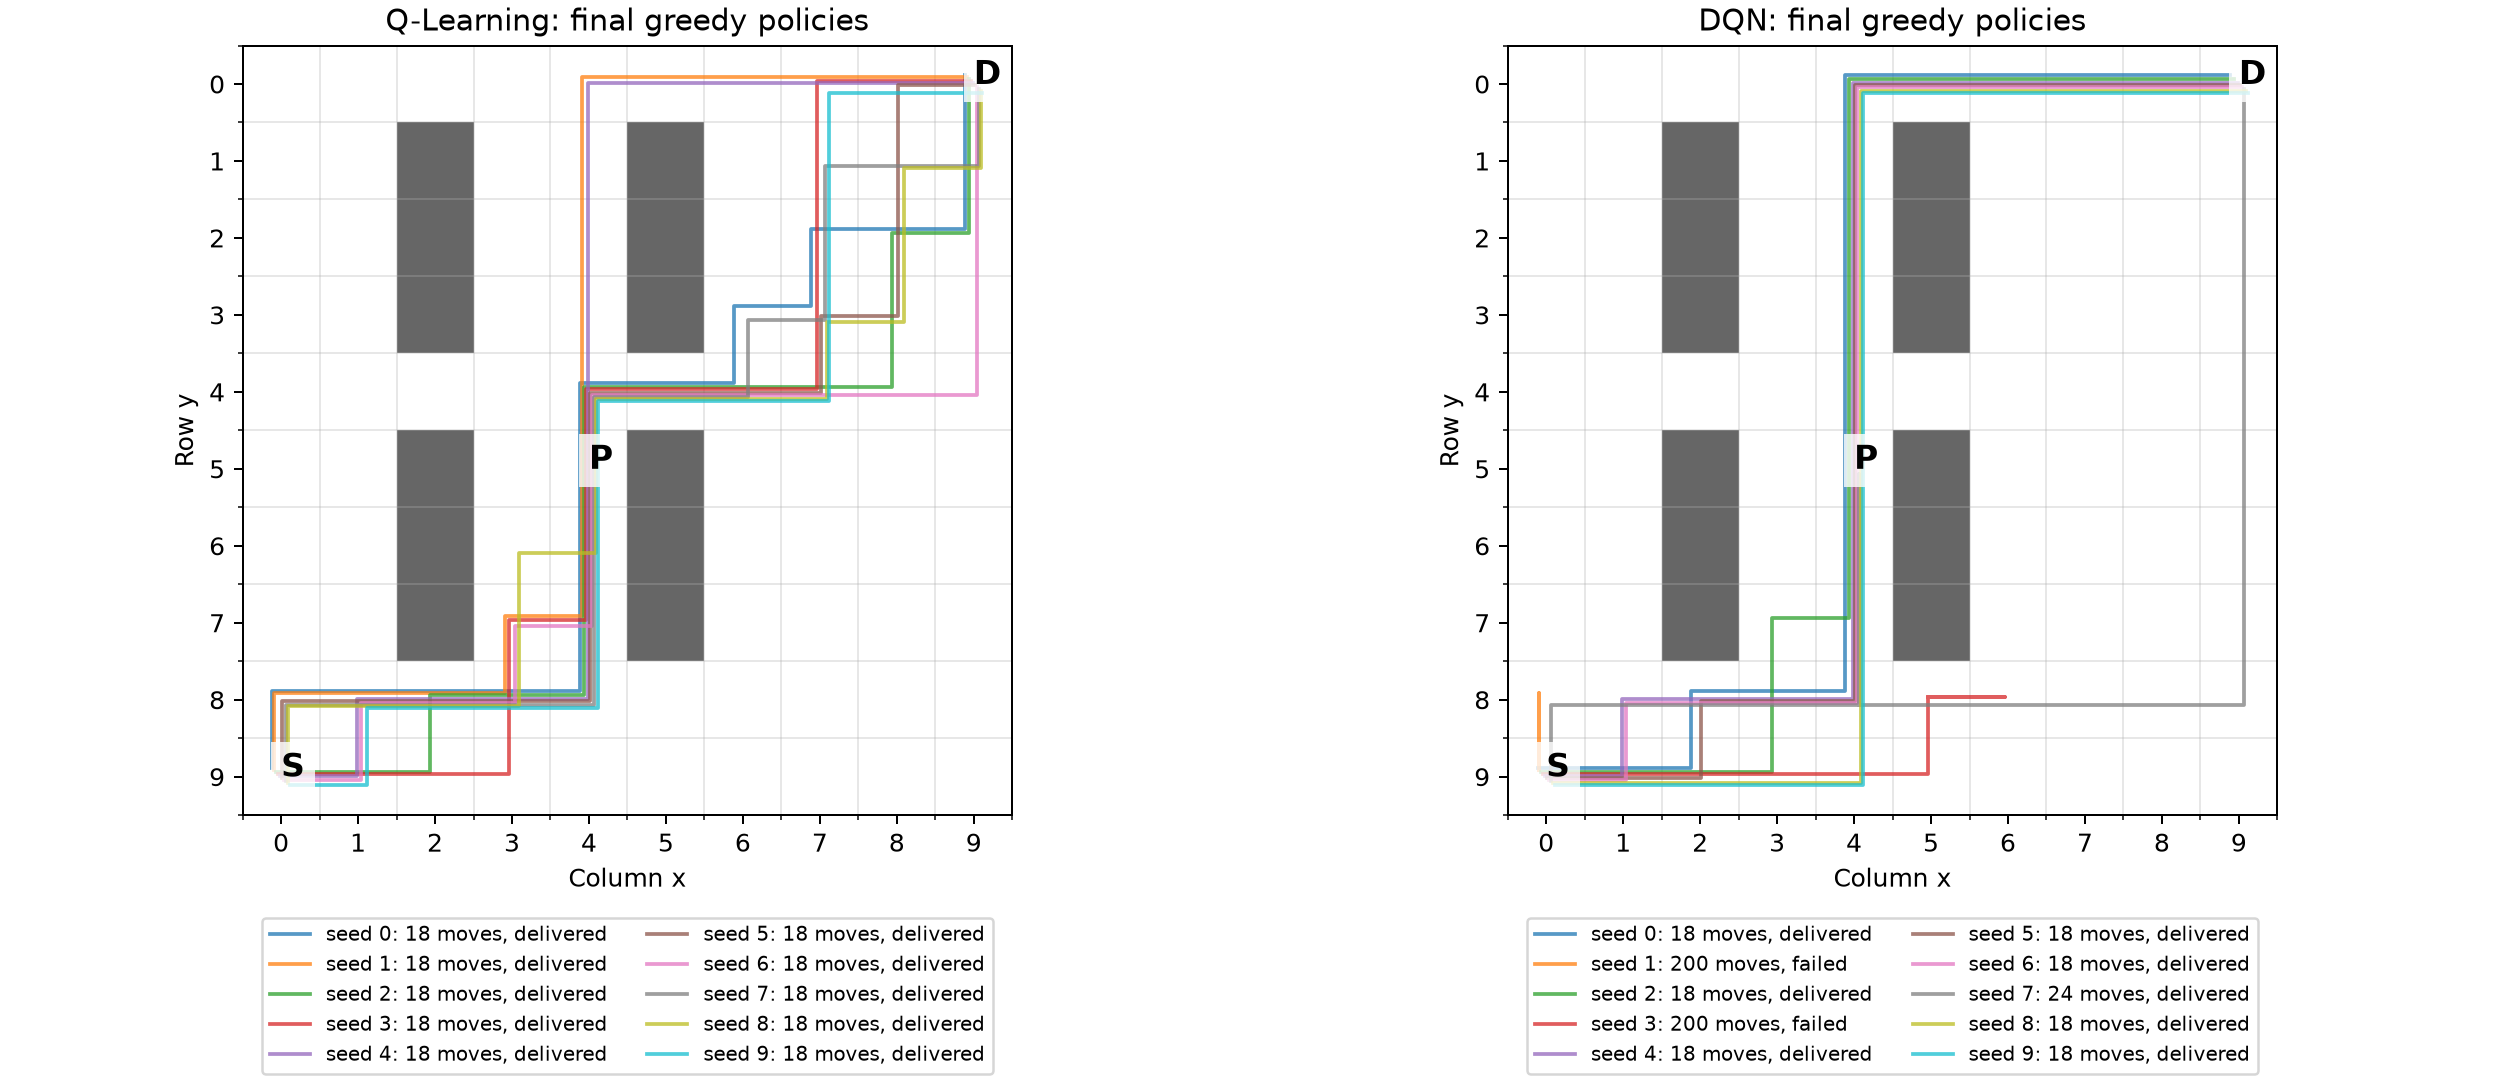

In [3]:
display(Image(filename=str(main / 'learning_curves.png')))
display(Image(filename=str(main / 'final_routes.png')))

## DQN failure analysis
Low collision rate does not guarantee delivery. Inspect the final rollout tails of the unsuccessful policies.

In [4]:
for method in ['q_learning', 'dqn']:
    for path in sorted((main / method).glob('seed_*/result.json')):
        result = json.loads(path.read_text())
        if not result['success']:
            print(method, 'seed', result['seed'], 'return', round(result['return'], 2), 'collisions', result['collisions'], 'tail', result['route'][-6:])

dqn seed 1 return -20.0 collisions 0 tail [[0, 8], [0, 9], [0, 8], [0, 9], [0, 8], [0, 9]]
dqn seed 3 return -20.0 collisions 0 tail [[6, 8], [5, 8], [6, 8], [5, 8], [6, 8], [5, 8]]


## Q-Learning robustness
The sweep describes alpha and epsilon-decay sensitivity. Main settings remain fixed; the sweep is not used to select the final reported policy.

In [5]:
rows = list(csv.DictReader((root / 'results/sweep/sweep_summary.csv').open()))
for r in rows:
    print(f"alpha={r['alpha']}, decay={r['epsilon_decay']}: optimal={r['optimal_policies']}/{r['n_runs']}, stable={float(r['stable_mean']):.1f} ± {float(r['stable_std']):.1f}, steps={float(r['environment_steps_mean']):.0f} ± {float(r['environment_steps_std']):.0f}")

alpha=0.05, decay=0.99: optimal=10/10, stable=169.0 ± 11.0, steps=71811 ± 410
alpha=0.05, decay=0.995: optimal=10/10, stable=165.0 ± 22.7, steps=76949 ± 467
alpha=0.05, decay=0.999: optimal=10/10, stable=179.0 ± 21.3, steps=123610 ± 1265
alpha=0.2, decay=0.99: optimal=10/10, stable=51.0 ± 8.8, steps=65721 ± 477
alpha=0.2, decay=0.995: optimal=10/10, stable=53.0 ± 8.2, steps=71346 ± 603
alpha=0.2, decay=0.999: optimal=10/10, stable=82.0 ± 10.3, steps=120838 ± 1975
alpha=0.5, decay=0.99: optimal=10/10, stable=36.0 ± 7.0, steps=64544 ± 483
alpha=0.5, decay=0.995: optimal=10/10, stable=47.0 ± 25.8, steps=70492 ± 647
alpha=0.5, decay=0.999: optimal=10/10, stable=60.0 ± 21.1, steps=119398 ± 739


## Frozen transfer and adaptation
The extension adds shelves at (3,5) and (4,6), changes the BFS optimum to 20 steps, and leaves observations, rewards and hyperparameters unchanged. All main final policies are tested frozen, then continued from their learned parameters for 1000 extra episodes. DQN starts fresh replay and Adam state. This is a deliberately route-blocking stress test; no diverse map suite or training-from-scratch comparison is included.

# Changed-layout transfer and adaptation

Two additional shelves at (3,5) and (4,6) block the original approaches to pickup. BFS optimum: 20 moves; undiscounted return 23.0.

This is a deliberately route-blocking stress test, not a representative random sample of warehouses. The new layout was excluded from the original main experiment and was not used to retune either algorithm.

Each of the ten base final checkpoints per method was evaluated frozen, then warm-started for 1000 additional episodes. DQN weights are retained; replay and Adam start fresh. Exploration restarts at 1.0 with the original decay.

| Method | Frozen successful policies | Adapted successful policies | Adapted optimal policies | Adapted return | Additional environment steps | Additional training seconds |
|---|---:|---:|---:|---:|---:|---:|
| q_learning | 0/10 | 10/10 | 10/10 | 23.00 ± 0.00 | 37109 ± 822 | 0.17 ± 0.00 |
| dqn | 0/10 | 10/10 | 10/10 | 23.00 ± 0.00 | 54141 ± 11843 | 5.99 ± 1.32 |

Adapted-policy metrics do not replace the main-layout metrics. A successful adaptation demonstrates relearning after new interaction, not zero-shot generalisation or faster learning than training from scratch. No from-scratch comparator or diverse map suite is included.


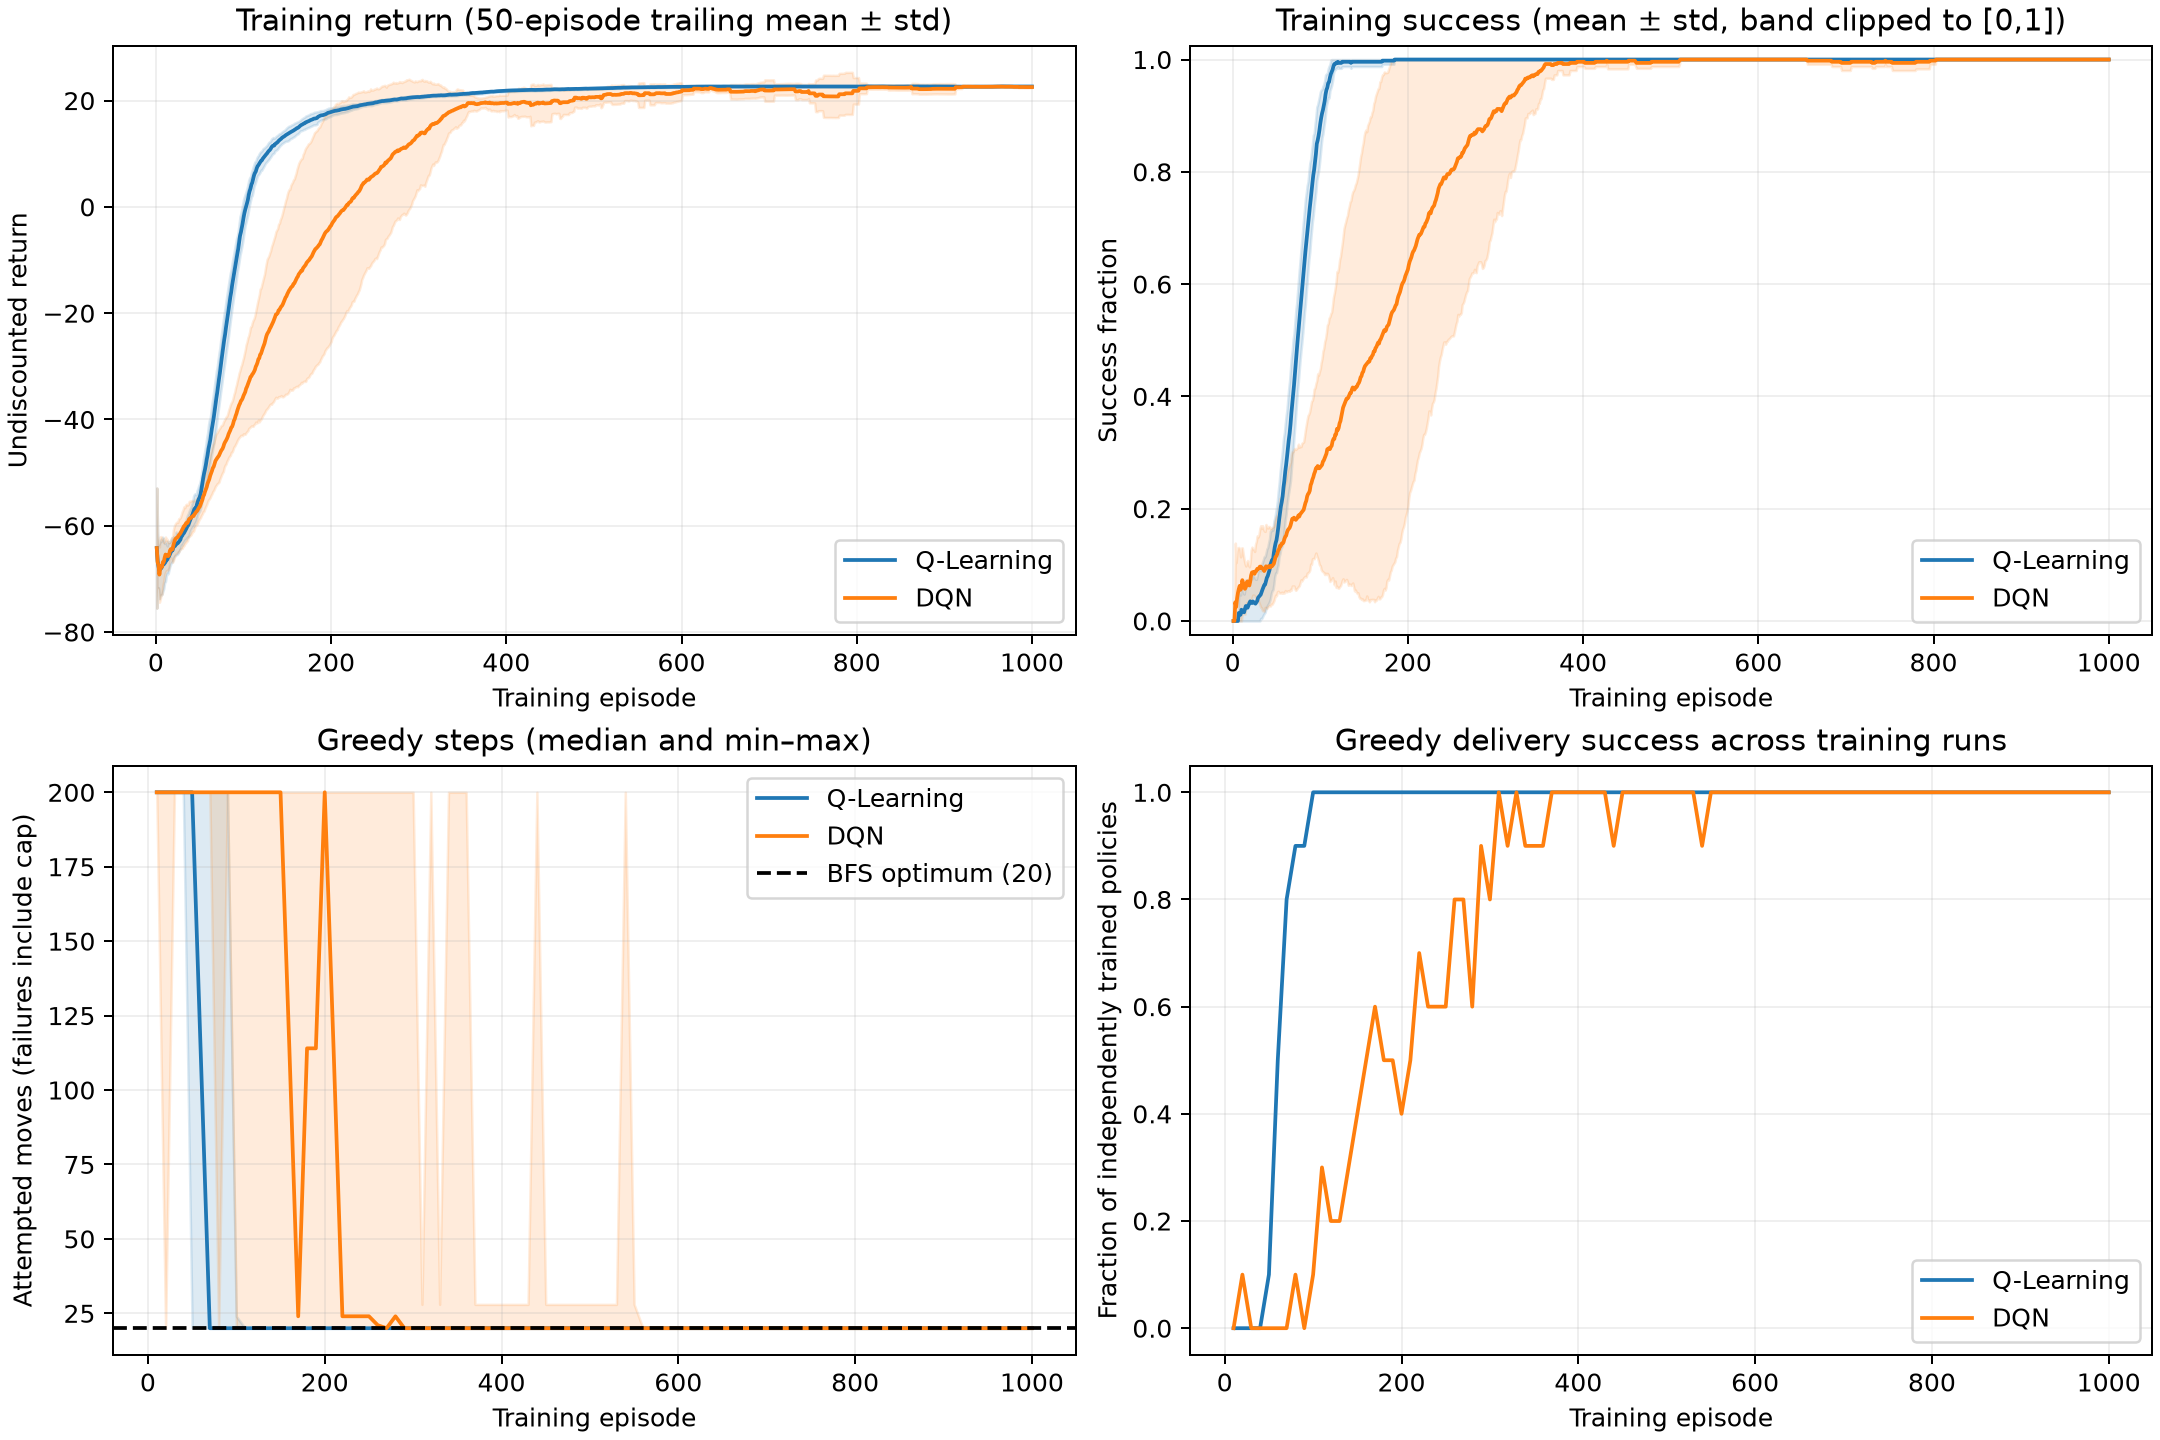

In [6]:
display(Markdown((adaptation / 'ADAPTATION.md').read_text()))
display(Image(filename=str(adaptation / 'learning_curves.png')))

## Verify saved results
Verification replays every saved model, checks the stored source snapshots and reconstructs random-policy episodes. Notebook verification is read-only except for writing its verification records.

In [7]:
from verify_results import verify, verify_sweep, verify_adaptation
verify(main)
verify_sweep(root / 'results/sweep')
verify(adaptation)
verify_adaptation(adaptation, main)

{
  "passed": true,
  "verified_policies": 20,
  "policies_by_method": {
    "q_learning": 10,
    "dqn": 10
  },
  "source_snapshot_files_checked": 6,
  "random_episodes": 1000,
  "checks": "source hashes, configuration, raw episode logs, convergence, saved-policy replay, random-baseline replay and summary statistics"
}
{
  "passed": true,
  "settings": 9,
  "runs": 90,
  "checks": "raw greedy checks, convergence, environment-step summaries and final saved-policy replay"
}


{
  "passed": true,
  "verified_policies": 20,
  "policies_by_method": {
    "q_learning": 10,
    "dqn": 10
  },
  "source_snapshot_files_checked": 17,
  "random_episodes": 0,
  "checks": "source hashes, configuration, raw episode logs, convergence, saved-policy replay, random-baseline replay and summary statistics"
}
{
  "passed": true,
  "frozen_policies_replayed": 20,
  "checks": "base model hashes, frozen replay and changed-layout success counts"
}


## Findings and remaining work
The main comparison favours Q-Learning under the tested configuration. Adaptation results demonstrate relearning after interaction with the changed layout, not zero-shot generalisation. Dashboard project number and Canvas upload requirements still require team confirmation. Future extensions can include a predeclared map suite and a from-scratch adaptation comparator.